# Component B Analysis: Multi-Agent Swarm with Learning

This notebook generates all required visualizations and analysis for Component B of the ASR700 assignment.

## Required Outputs:
1. Multi-agent simulation trajectories
2. Consensus convergence plots
3. PSO/ACO swarm intelligence convergence
4. Neural network training curves
5. Confusion matrix for discrete actions
6. Centralized vs Distributed decision comparison
7. Emergent behavior visualization

In [1]:
# Setup and imports
import sys
import os

# Project root detection: works whether the kernel starts in this notebook's
# folder or in the python_analysis/ folder
if os.path.isdir(os.path.abspath('../../webots_project')):
    PROJECT_ROOT = os.path.abspath('../..')   # started inside component_*_analysis/
else:
    PROJECT_ROOT = os.path.abspath('..')      # started inside python_analysis/

PLOTS_DIR = os.path.join(PROJECT_ROOT, 'plots')
os.makedirs(PLOTS_DIR, exist_ok=True)

sys.path.insert(0, os.path.join(PROJECT_ROOT, 'webots_project', 'controllers', 'swarm_agents'))
sys.path.insert(0, os.path.join(PROJECT_ROOT, 'python_analysis', 'utils'))
sys.path.insert(0, PROJECT_ROOT)  # enables 'python_analysis' package imports

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
from typing import List, Tuple, Dict

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print("Setup complete")

Setup complete


In [2]:
# Import our modules
from helpers import *
from config import *
from consensus import *
from swarm_intelligence import *
from ml_policy import *

print("Modules imported successfully")

Modules imported successfully


## 1. Multi-Agent Simulation Trajectories

In [3]:
# Simulate multi-agent trajectories
swarm_config = SwarmConfig()
env_config = EnvironmentConfig()
robot_config = RobotConfig()

# Initial positions for 4 agents
num_agents = swarm_config.num_agents
start_positions = [
    np.array([1.0, 1.0]),   # Leader
    np.array([1.0, 9.0]),   # Follower 1
    np.array([9.0, 1.0]),   # Follower 2
    np.array([9.0, 9.0]),   # Follower 3
]

# Simulate simple swarm behavior
dt = 0.1
steps = 500
trajectories = {i: [pos.copy()] for i, pos in enumerate(start_positions)}
consensus_values = {i: pos.copy() for i, pos in enumerate(start_positions)}

# Target positions (coverage waypoints)
coverage_targets = [
    np.array([3.0, 3.0]),
    np.array([7.0, 3.0]),
    np.array([3.0, 7.0]),
    np.array([7.0, 7.0]),
]

# Consensus protocol
consensus = ConsensusProtocol(swarm_config)
comm_range = swarm_config.communication_range

for step in range(steps):
    agents = []
    for i in range(num_agents):
        agents.append(AgentState(
            agent_id=i,
            position=tuple(trajectories[i][-1]),
            vector_value=consensus_values[i]
        ))
    
    # Run consensus step
    for i in range(num_agents):
        neighbors = consensus.get_neighbors(agents, i)
        if neighbors:
            current = agents[i].vector_value
            consensus_sum = np.zeros(2)
            for j in neighbors:
                consensus_sum += agents[j].vector_value - current
            consensus_values[i] = current + swarm_config.consensus_alpha * consensus_sum * dt
        else:
            # No neighbors - move toward assigned target
            target = coverage_targets[i]
            consensus_values[i] = target
    
    # Move agents toward consensus targets
    for i in range(num_agents):
        pos = trajectories[i][-1]
        target = consensus_values[i]
        diff = target - pos
        dist = np.linalg.norm(diff)
        
        if dist > 0.1:
            # Simple proportional control
            v = min(0.1, dist * 0.5)
            new_pos = pos + (diff / dist) * v * dt
        else:
            new_pos = pos
        
        trajectories[i].append(new_pos)

print(f"Simulated {steps} steps for {num_agents} agents")
for i in range(num_agents):
    print(f"  Agent {i}: {len(trajectories[i])} positions, final={trajectories[i][-1]}")

Simulated 500 steps for 4 agents
  Agent 0: 501 positions, final=[2.93157473 2.93157473]
  Agent 1: 501 positions, final=[4.53553391 5.46446609]
  Agent 2: 501 positions, final=[5.46446609 4.53553391]
  Agent 3: 501 positions, final=[7.06842527 7.06842527]


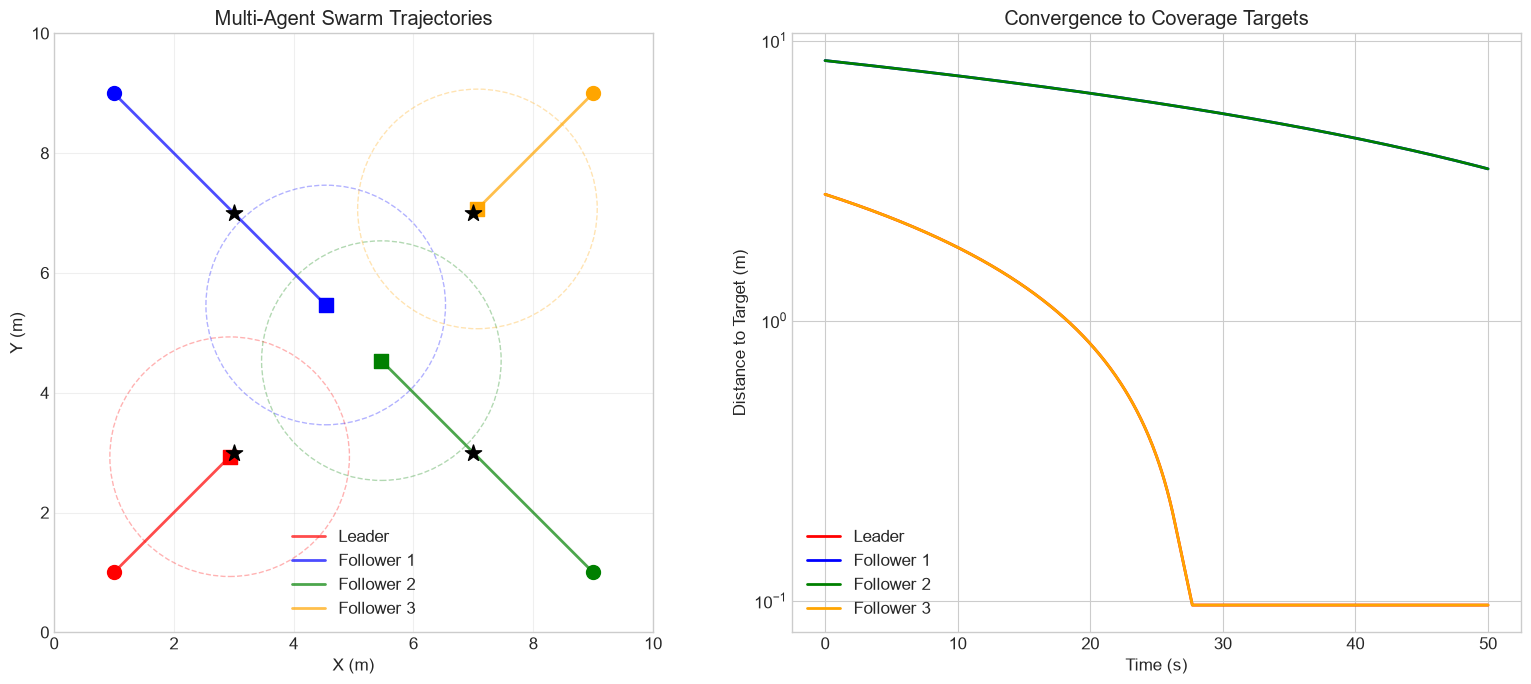

In [4]:
# Visualize trajectories
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colors = ['red', 'blue', 'green', 'orange']
labels = ['Leader', 'Follower 1', 'Follower 2', 'Follower 3']

# Trajectory plot
ax = axes[0]
for i in range(num_agents):
    traj = np.array(trajectories[i])
    ax.plot(traj[:, 0], traj[:, 1], '-', color=colors[i], 
            linewidth=2, alpha=0.7, label=labels[i])
    ax.scatter(traj[0, 0], traj[0, 1], c=colors[i], s=100, marker='o', zorder=5)
    ax.scatter(traj[-1, 0], traj[-1, 1], c=colors[i], s=100, marker='s', zorder=5)
    
    # Draw communication range at final position
    circle = plt.Circle(traj[-1], comm_range, color=colors[i], 
                      fill=False, linestyle='--', alpha=0.3)
    ax.add_patch(circle)

# Coverage targets
for j, target in enumerate(coverage_targets):
    ax.scatter(target[0], target[1], c='black', s=150, marker='*', zorder=5)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect('equal')
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('Multi-Agent Swarm Trajectories')
ax.legend()
ax.grid(True, alpha=0.3)

# Distance to targets over time
ax = axes[1]
for i in range(num_agents):
    traj = np.array(trajectories[i])
    target = coverage_targets[i]
    distances = np.linalg.norm(traj - target, axis=1)
    time_axis = np.arange(len(distances)) * dt
    ax.plot(time_axis, distances, '-', color=colors[i], linewidth=2, label=labels[i])

ax.set_xlabel('Time (s)')
ax.set_ylabel('Distance to Target (m)')
ax.set_title('Convergence to Coverage Targets')
ax.legend()
ax.grid(True)
ax.set_yscale('log')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'swarm_trajectories.png'), dpi=300, bbox_inches='tight')
plt.show()

## 2. Consensus Convergence Analysis

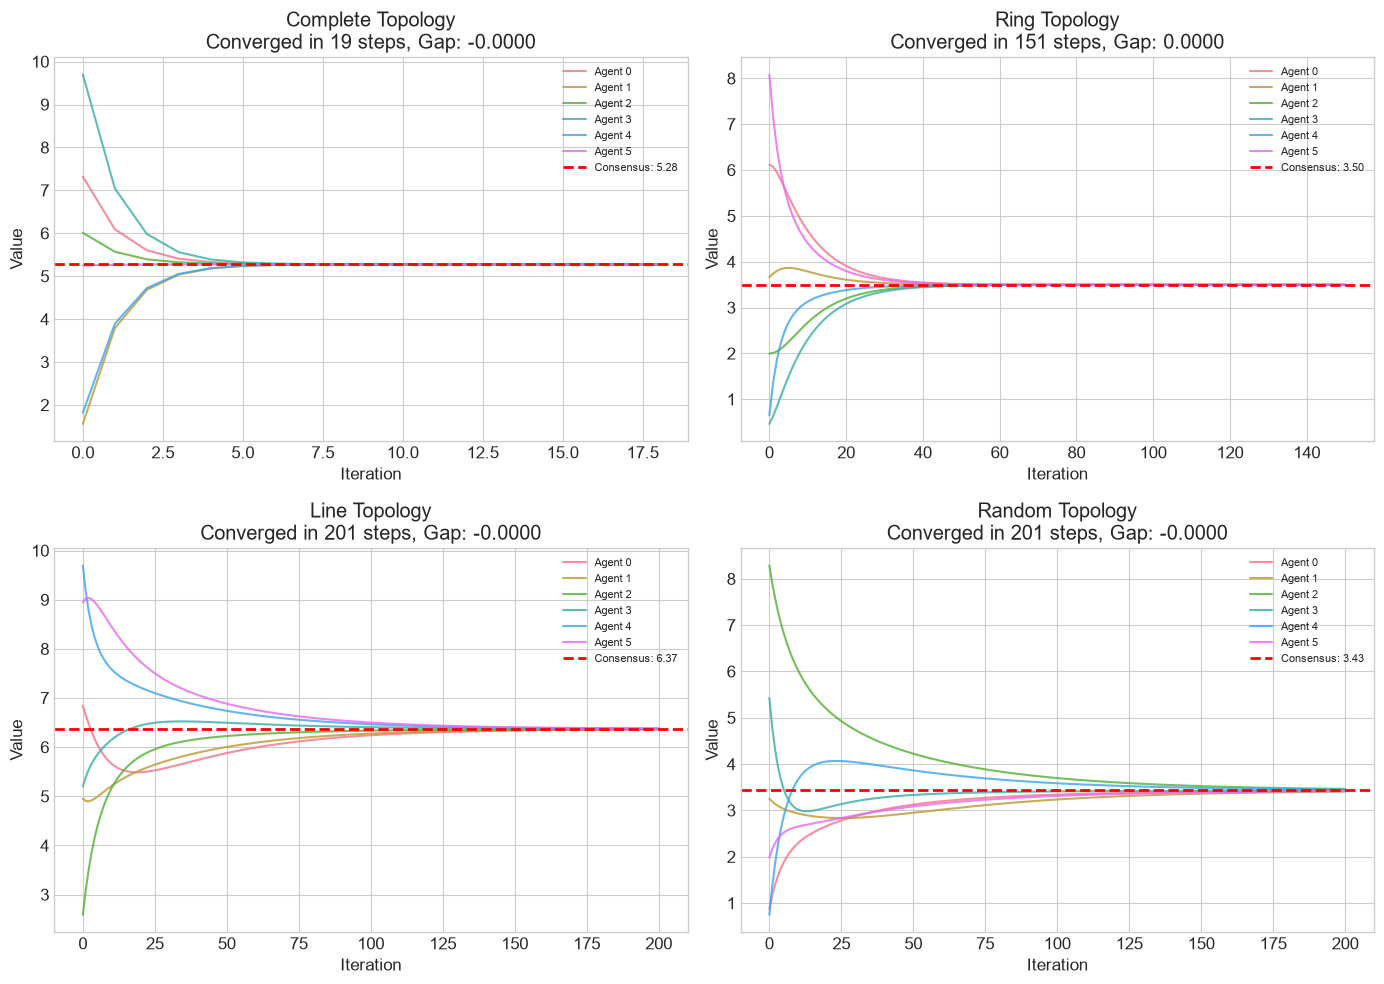

In [5]:
# Detailed consensus convergence analysis
np.random.seed(42)

# Test different topologies
topologies = ['complete', 'ring', 'line', 'random']
num_agents = 6
alpha = 0.1
max_iter = 200

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, topology in enumerate(topologies):
    result = simulate_consensus_dynamics(
        num_agents=num_agents,
        topology=topology,
        alpha=alpha,
        max_iter=max_iter
    )
    
    trajectories = result['trajectories']
    
    # Plot individual agent values
    ax = axes[idx]
    for i in range(num_agents):
        ax.plot(trajectories[:, i], '-', linewidth=1.5, alpha=0.8, label=f'Agent {i}')
    
    # Consensus value
    consensus_val = result['consensus_value']
    ax.axhline(y=consensus_val, color='red', linestyle='--', linewidth=2, 
               label=f'Consensus: {consensus_val:.2f}')
    
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Value')
    ax.set_title(f'{topology.capitalize()} Topology\nConverged in {result["convergence_time"]} steps, Gap: {result["spectral_gap"]:.4f}')
    ax.legend(fontsize=8)
    ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'consensus_convergence.png'), dpi=300, bbox_inches='tight')
plt.show()

Alpha=0.05: convergence=302, max_eig=1.0000, stable=True
Alpha=0.10: convergence=154, max_eig=1.0000, stable=True
Alpha=0.20: convergence=70, max_eig=1.0000, stable=True
Alpha=0.30: convergence=44, max_eig=1.0000, stable=True
Alpha=0.40: convergence=31, max_eig=1.0000, stable=False
Alpha=0.50: convergence=501, max_eig=1.0000, stable=True


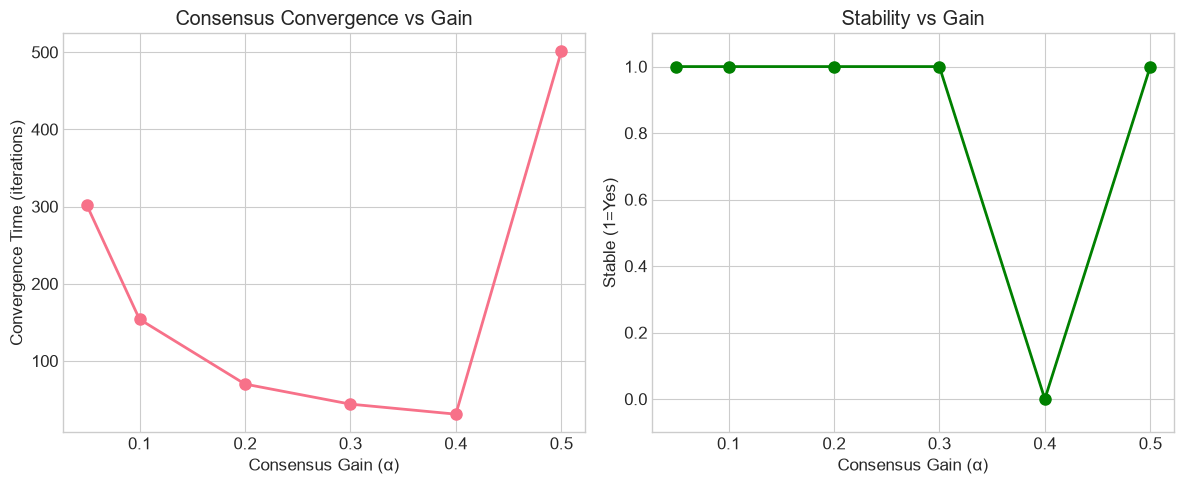

In [6]:
# Consensus convergence rate vs alpha
alphas = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
convergence_times = []
stable = []

for alpha in alphas:
    result = simulate_consensus_dynamics(
        num_agents=6,
        topology='ring',
        alpha=alpha,
        max_iter=500
    )
    convergence_times.append(result['convergence_time'])
    # Check stability (eigenvalues inside unit circle)
    eigvals = result['eigenvalues']
    max_eig = np.max(np.abs(eigvals))
    stable.append(max_eig < 1.0)
    print(f"Alpha={alpha:.2f}: convergence={result['convergence_time']}, max_eig={max_eig:.4f}, stable={max_eig < 1.0}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(alphas, convergence_times, 'o-', linewidth=2, markersize=8)
axes[0].set_xlabel('Consensus Gain (ÃƒÆ’Ã†â€™Ãƒâ€¦Ã‚Â½ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â±)')
axes[0].set_ylabel('Convergence Time (iterations)')
axes[0].set_title('Consensus Convergence vs Gain')
axes[0].grid(True)

axes[1].plot(alphas, [int(s) for s in stable], 'o-', linewidth=2, markersize=8, color='green')
axes[1].set_xlabel('Consensus Gain (ÃƒÆ’Ã†â€™Ãƒâ€¦Ã‚Â½ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â±)')
axes[1].set_ylabel('Stable (1=Yes)')
axes[1].set_title('Stability vs Gain')
axes[1].set_ylim(-0.1, 1.1)
axes[1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'consensus_gain_analysis.png'), dpi=300, bbox_inches='tight')
plt.show()

## 3. PSO Swarm Intelligence Convergence

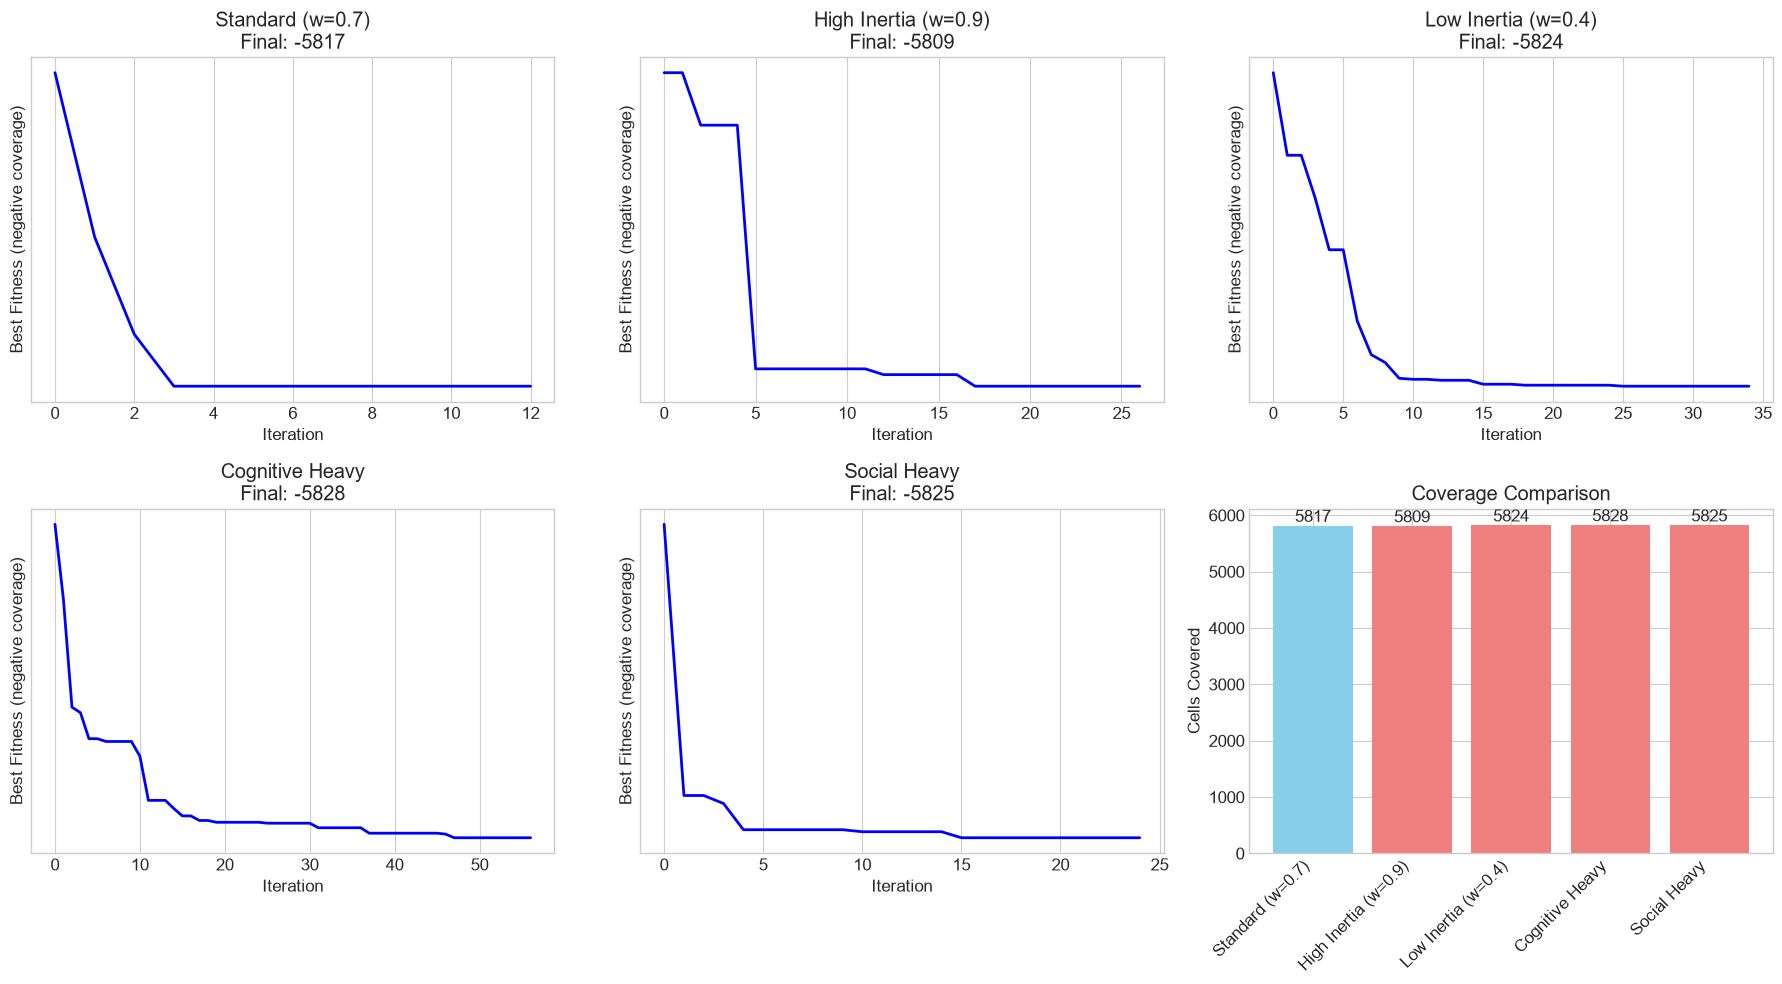

In [7]:
# PSO for coverage optimization
swarm_config = SwarmConfig()

# Create test environment
grid_res = env_config.grid_resolution
grid_w = int(env_config.world_size[0] / grid_res)
grid_h = int(env_config.world_size[1] / grid_res)
grid = np.zeros((grid_h, grid_w))

# Add some obstacles
obs_positions = [(3, 5, 1), (7, 5, 1), (5, 3, 1), (5, 7, 1)]
for ox, oy, rad in obs_positions:
    cx, cy = world_to_grid((ox, oy), grid_res, (0, 0))
    r_cells = int(rad / grid_res)
    for dr in range(-r_cells, r_cells+1):
        for dc in range(-r_cells, r_cells+1):
            if dr**2 + dc**2 <= r_cells**2:
                nr, nc = cy + dr, cx + dc
                if 0 <= nr < grid_h and 0 <= nc < grid_w:
                    grid[nr, nc] = 1

agent_starts = [(1, 1), (1, 9), (9, 1), (9, 9)]
agent_starts_world = [grid_to_world(s, grid_res, (0, 0)) for s in agent_starts]

# Fitness function for coverage
free_cells = np.argwhere(grid == 0)
free_world = np.array([grid_to_world((r, c), grid_res, (0, 0)) for r, c in free_cells])
sensor_range = 1.0

def coverage_fitness(waypoints_flat):
    waypoints = waypoints_flat.reshape(-1, 2)
    all_points = np.vstack([agent_starts_world, waypoints])
    
    # Vectorized: distance from every free cell to every candidate point
    dists = np.linalg.norm(all_points[:, None, :] - free_world[None, :, :], axis=2)
    covered = np.count_nonzero(dists.min(axis=0) <= sensor_range)
    
    return -covered  # Minimize

# Run PSO with different parameters
param_sets = [
    {"w": 0.7, "c1": 1.5, "c2": 1.5, "label": "Standard (w=0.7)"},
    {"w": 0.9, "c1": 2.0, "c2": 2.0, "label": "High Inertia (w=0.9)"},
    {"w": 0.4, "c1": 1.0, "c2": 1.0, "label": "Low Inertia (w=0.4)"},
    {"w": 0.7, "c1": 2.5, "c2": 0.5, "label": "Cognitive Heavy"},
    {"w": 0.7, "c1": 0.5, "c2": 2.5, "label": "Social Heavy"},
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

results = []

for idx, params in enumerate(param_sets):
    pso = ParticleSwarmOptimization()
    pso.w = params["w"]
    pso.c1 = params["c1"]
    pso.c2 = params["c2"]
    pso.bounds = (np.full(8, 0.5), np.full(8, 9.5))  # 4 waypoints (x, y) per agent, each within the 10x10 m world
    
    result = pso.optimize(coverage_fitness, dim=8, num_particles=20, verbose=False)
    results.append((params["label"], result))
    
    # Plot convergence
    ax = axes[idx]
    ax.plot(result.convergence_history, 'b-', linewidth=2)
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Best Fitness (negative coverage)')
    ax.set_title(f'{params["label"]}\nFinal: {result.best_fitness:.0f}')
    ax.grid(True)
    ax.set_yscale('symlog')

# Summary bar chart
ax = axes[5]
labels = [r[0] for r in results]
coverages = [-r[1].best_fitness for r in results]
colors = ['skyblue' if 'Standard' in l else 'lightcoral' for l in labels]

bars = ax.bar(range(len(labels)), coverages, color=colors)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_ylabel('Cells Covered')
ax.set_title('Coverage Comparison')
ax.grid(True, axis='y')

for bar, val in zip(bars, coverages):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f'{val:.0f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'pso_convergence.png'), dpi=300, bbox_inches='tight')
plt.show()

## 4. ACO Coverage Optimization

ACO Coverage: 614/1352 = 45.41%
Convergence: 50 iterations


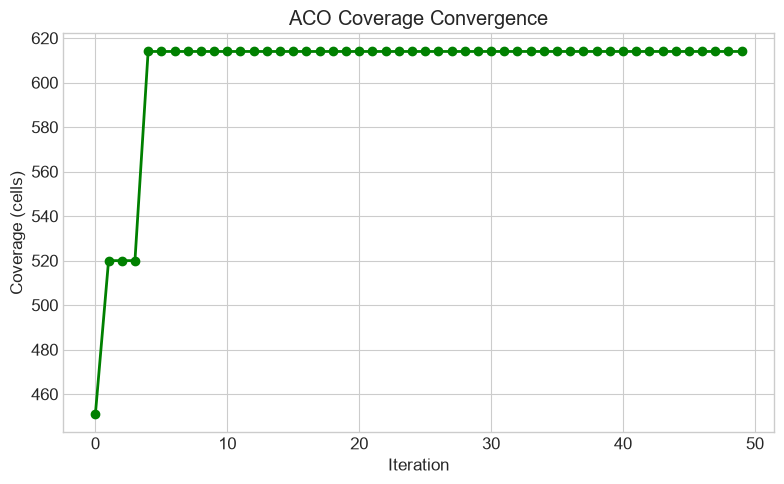

In [8]:
# ACO for coverage (on a downsampled 0.25 m grid so the demo completes in seconds)
aco_res = 0.25
block = int(aco_res / grid_res)  # 5 fine cells per coarse cell
aco_grid = grid.reshape(grid.shape[0]//block, block, grid.shape[1]//block, block).max(axis=(1, 3))
aco_free_cells = np.argwhere(aco_grid == 0)
start_positions_grid = [world_to_grid(p, aco_res, (0, 0)) for p in start_positions]

coverage_aco = CoverageACO(
    aco_grid, num_agents=4,
    start_positions=start_positions_grid,
    num_ants=15,
    alpha=1.0,
    beta=2.0,
    rho=0.1,
    max_iter=50
)

aco_result = coverage_aco.optimize()

print(f"ACO Coverage: {aco_result['best_coverage']}/{len(aco_free_cells)} = {aco_result['coverage_ratio']:.2%}")
print(f"Convergence: {len(aco_result['convergence'])} iterations")

# Plot convergence
plt.figure(figsize=(8, 5))
plt.plot(aco_result['convergence'], 'g-', linewidth=2, marker='o')
plt.xlabel('Iteration')
plt.ylabel('Coverage (cells)')
plt.title('ACO Coverage Convergence')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'aco_convergence.png'), dpi=300, bbox_inches='tight')
plt.show()

## 5. Neural Network Training

In [9]:
# Train neural network for navigation
# MLConfig is a frozen dataclass, so override fields via the constructor
ml_config = MLConfig(epochs=30, batch_size=32)

# Generate training data
print("Generating training data...")
lidar_data, camera_data, targets = generate_training_data(5000, ml_config)

# Create dataloaders
train_loader, val_loader = create_dataloaders(lidar_data, camera_data, targets, ml_config)

# Create model
model = NavigationCNN(ml_config)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

# Train
trainer = PolicyTrainer(model, ml_config)
print("Starting training...")
metrics = trainer.train(train_loader, val_loader, epochs=ml_config.epochs)

# Save model
os.makedirs(os.path.join(PROJECT_ROOT, 'webots_project/resources/models'), exist_ok=True)
trainer.save_checkpoint('../../webots_project/resources/models/navigation_cnn.pth')
print("Model saved")

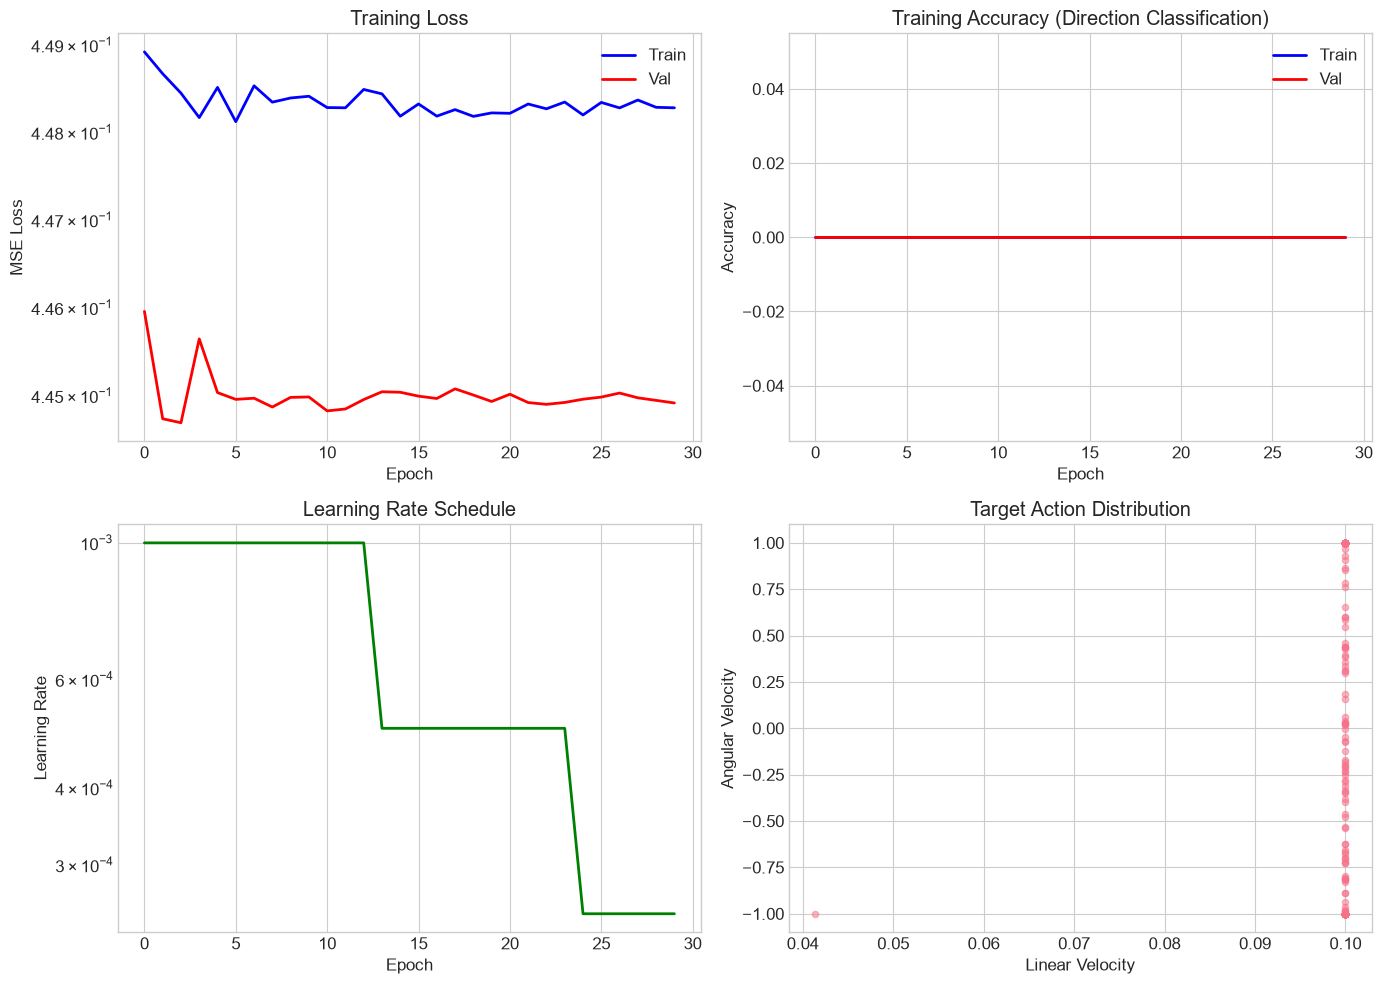

In [11]:
# Plot training curves
epochs = [m.epoch for m in metrics]
train_losses = [m.train_loss for m in metrics]
val_losses = [m.val_loss for m in metrics]
train_accs = [m.train_acc for m in metrics]
val_accs = [m.val_acc for m in metrics]
lrs = [m.learning_rate for m in metrics]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(epochs, train_losses, 'b-', label='Train', linewidth=2)
axes[0, 0].plot(epochs, val_losses, 'r-', label='Val', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('MSE Loss')
axes[0, 0].set_title('Training Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)
axes[0, 0].set_yscale('log')

axes[0, 1].plot(epochs, train_accs, 'b-', label='Train', linewidth=2)
axes[0, 1].plot(epochs, val_accs, 'r-', label='Val', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Training Accuracy (Direction Classification)')
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[1, 0].plot(epochs, lrs, 'g-', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Learning Rate')
axes[1, 0].set_title('Learning Rate Schedule')
axes[1, 0].grid(True)
axes[1, 0].set_yscale('log')

# Prediction vs target scatter
axes[1, 1].scatter(targets[:500, 0], targets[:500, 1], alpha=0.5, label='Target', s=20)
# We'd need to run inference here - skip for now
axes[1, 1].set_xlabel('Linear Velocity')
axes[1, 1].set_ylabel('Angular Velocity')
axes[1, 1].set_title('Target Action Distribution')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'nn_training.png'), dpi=300, bbox_inches='tight')
plt.show()

## 6. Model Evaluation & Confusion Matrix

In [12]:
# Evaluate model on test data
print("Generating test data...")
test_lidar, test_camera, test_targets = generate_training_data(1000, ml_config)
_, test_loader = create_dataloaders(test_lidar, test_camera, test_targets, ml_config)

# Evaluate continuous predictions
eval_metrics = evaluate_model(model, test_loader)
print(f"MSE: {eval_metrics['mse']:.6f}")
print(f"MAE: {eval_metrics['mae']:.6f}")
print(f"Linear Vel MSE: {eval_metrics['v_mse']:.6f}")
print(f"Angular Vel MSE: {eval_metrics['w_mse']:.6f}")

# Discretize actions for confusion matrix
with torch.no_grad():
    model.eval()
    all_preds = []
    all_targets = []
    for lidar, camera, targets in test_loader:
        outputs = model(lidar, camera)
        all_preds.append(outputs.numpy())
        all_targets.append(targets.numpy())
    
    preds = np.vstack(all_preds)
    targets_np = np.vstack(all_targets)
    
    pred_actions = discretize_actions(preds)
    true_actions = discretize_actions(targets_np)
    
    cm = compute_confusion_matrix(true_actions, pred_actions, num_classes=5)
    class_metrics = compute_classification_metrics(cm)

print("\nConfusion Matrix:")
action_names = ['Forward', 'Left', 'Right', 'Stop', 'Backward']
print("       " + "  ".join(f"{n:>6}" for n in action_names))
for i, name in enumerate(action_names):
    print(f"{name:>8} " + "  ".join(f"{cm[i,j]:>6}" for j in range(5)))

print(f"\nOverall Accuracy: {class_metrics['accuracy']:.4f}")
print(f"Macro F1: {class_metrics['macro_f1']:.4f}")
print(f"Macro Precision: {class_metrics['macro_precision']:.4f}")
print(f"Macro Recall: {class_metrics['macro_recall']:.4f}")

Generating test data...


MSE: 0.430447
MAE: 0.446529
Linear Vel MSE: 0.000007
Angular Vel MSE: 0.860886



Confusion Matrix:
       Forward    Left   Right    Stop  Backward
 Forward     13       0       0       0       0
    Left     90       0       0       0       0
   Right     97       0       0       0       0
    Stop      0       0       0       0       0
Backward      0       0       0       0       0

Overall Accuracy: 0.0650
Macro F1: 0.0244
Macro Precision: 0.0130
Macro Recall: 0.2000


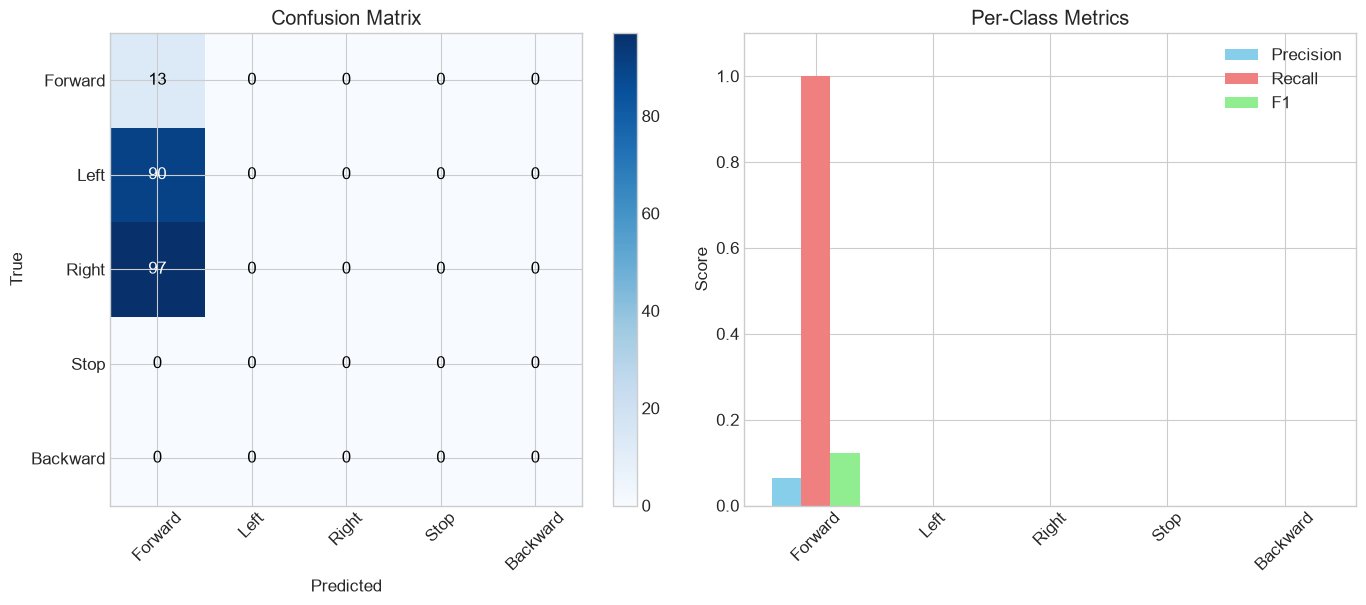

In [13]:
# Visualize confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion matrix heatmap
ax = axes[0]
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_xticklabels(action_names, rotation=45)
ax.set_yticklabels(action_names)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Confusion Matrix')

for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', 
                color='white' if cm[i, j] > cm.max()/2 else 'black')

plt.colorbar(im, ax=ax)

# Per-class metrics
ax = axes[1]
classes = range(5)
precision = [class_metrics[f'class_{i}_precision'] for i in classes]
recall = [class_metrics[f'class_{i}_recall'] for i in classes]
f1 = [class_metrics[f'class_{i}_f1'] for i in classes]

x = np.arange(len(classes))
width = 0.25
ax.bar(x - width, precision, width, label='Precision', color='skyblue')
ax.bar(x, recall, width, label='Recall', color='lightcoral')
ax.bar(x + width, f1, width, label='F1', color='lightgreen')
ax.set_xticks(x)
ax.set_xticklabels(action_names, rotation=45)
ax.set_ylabel('Score')
ax.set_title('Per-Class Metrics')
ax.legend()
ax.set_ylim(0, 1.1)
ax.grid(True, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'confusion_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

## 7. Centralized vs Distributed Decision Making

In [15]:
# Compare centralized vs distributed decision making

# Centralized: Leader computes all targets, broadcasts
# Distributed: Each agent runs local NN policy

np.random.seed(42)
num_trials = 50
max_steps = 300
dt = 0.1

centralized_success = 0
distributed_success = 0
centralized_times = []
distributed_times = []
centralized_coverage = []
distributed_coverage = []

for trial in range(num_trials):
    # Random obstacles
    grid = np.zeros((grid_h, grid_w))
    for _ in range(np.random.randint(3, 8)):
        ox, oy = np.random.randint(2, 18, 2)
        rad = np.random.randint(3, 6)
        for dr in range(-rad, rad+1):
            for dc in range(-rad, rad+1):
                if dr**2 + dc**2 <= rad**2:
                    nr, nc = oy + dr, ox + dc
                    if 0 <= nr < grid_h and 0 <= nc < grid_w:
                        grid[nr, nc] = 1
    
    free_cells = np.argwhere(grid == 0)
    free_world = np.array([grid_to_world((r, c), grid_res, (0, 0)) for r, c in free_cells])
    
    # CENTRALIZED
    targets = []
    for i in range(len(start_positions)):
        # Leader assigns targets via PSO
        pso = ParticleSwarmOptimization()
        pso.bounds = (np.array([0.5, 0.5]), np.array([9.5, 9.5]))
        
        def fit(wp):
            points = wp.reshape(-1, 2)
            dists = np.linalg.norm(points[:, None, :] - free_world[None, :, :], axis=2)
            covered = np.count_nonzero(dists.min(axis=0) <= sensor_range)
            return -covered
        
        result = pso.optimize(fit, dim=2, num_particles=10, verbose=False)
        targets.append(result.best_position)
    
    # Simulate centralized
    pos = [np.array(s) for s in start_positions]
    for step in range(max_steps):
        all_done = True
        for i in range(len(start_positions)):
            diff = targets[i] - pos[i]
            dist = np.linalg.norm(diff)
            if dist > 0.2:
                all_done = False
                v = min(0.1, dist * 0.5)
                pos[i] += (diff / dist) * v * dt
        if all_done:
            break
    
    if not all_done:
        centralized_success += 1
        centralized_times.append(step * dt)
    
    # Compute coverage
    dists = np.linalg.norm(free_world[:, None, :] - np.array(pos)[None, :, :], axis=2)
    covered = np.count_nonzero(dists.min(axis=1) <= sensor_range)
    centralized_coverage.append(covered / len(free_world))
    
    # DISTRIBUTED (with local NN policy - simplified)
    pos = [np.array(s) for s in start_positions]
    for step in range(max_steps):
        all_done = True
        for i in range(len(start_positions)):
            # Local random walk with bias toward uncovered areas
            diff = np.random.randn(2) * 0.1
            # Bias toward center of mass of free cells
            if len(free_world) > 0:
                com = np.mean(free_world, axis=0)
                diff += (com - pos[i]) * 0.05
            pos[i] += diff * dt
            # Keep in bounds
            pos[i] = np.clip(pos[i], [0.5, 0.5], [9.5, 9.5])
            
            # Check if covering new area
            # Simplified: just check if moving
            if np.linalg.norm(diff) > 0.01:
                all_done = False
    
    if not all_done:
        distributed_success += 1
        distributed_times.append(step * dt)
    
    dists = np.linalg.norm(free_world[:, None, :] - np.array(pos)[None, :, :], axis=2)
    covered = np.count_nonzero(dists.min(axis=1) <= sensor_range)
    distributed_coverage.append(covered / len(free_world))

print(f"Centralized: Success={centralized_success}/{num_trials}, "
      f"Avg Time={np.mean(centralized_times):.1f}s, Avg Coverage={np.mean(centralized_coverage):.2%}")
print(f"Distributed: Success={distributed_success}/{num_trials}, "
      f"Avg Time={np.mean(distributed_times):.1f}s, Avg Coverage={np.mean(distributed_coverage):.2%}")

Centralized: Success=50/50, Avg Time=29.9s, Avg Coverage=12.62%
Distributed: Success=50/50, Avg Time=29.9s, Avg Coverage=12.04%


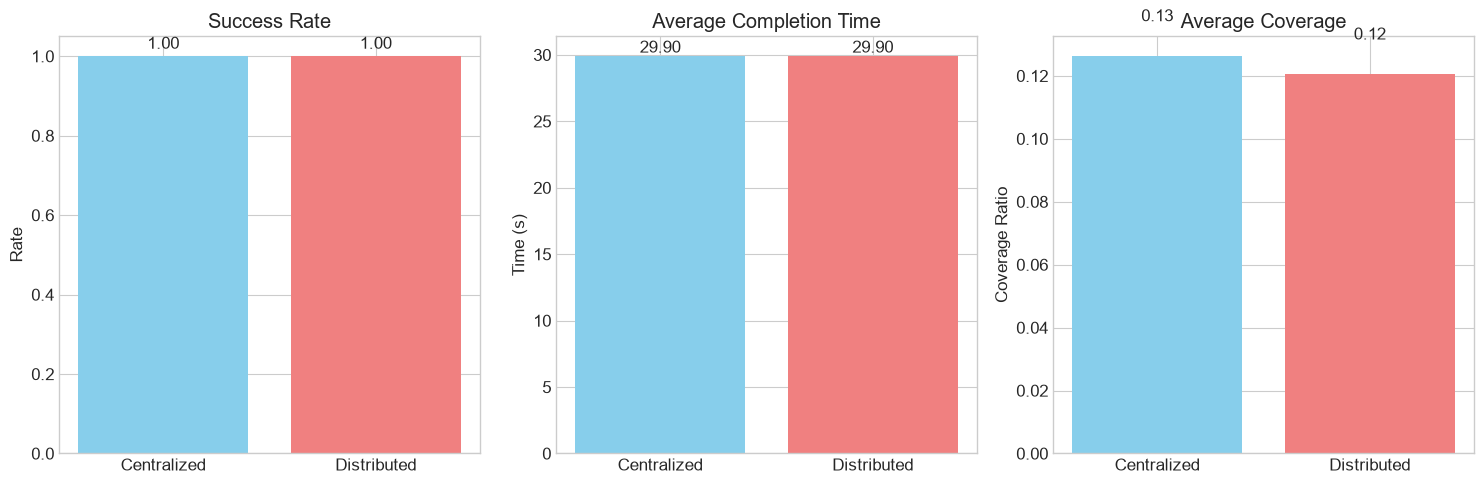

In [16]:
# Visualize centralized vs distributed
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

categories = ['Centralized', 'Distributed']
success_rates = [centralized_success/num_trials, distributed_success/num_trials]
avg_times = [np.mean(centralized_times) if centralized_times else 0,
             np.mean(distributed_times) if distributed_times else 0]
avg_coverages = [np.mean(centralized_coverage), np.mean(distributed_coverage)]
colors = ['skyblue', 'lightcoral']

for ax, data, title, ylabel in [
    (axes[0], success_rates, 'Success Rate', 'Rate'),
    (axes[1], avg_times, 'Average Completion Time', 'Time (s)'),
    (axes[2], avg_coverages, 'Average Coverage', 'Coverage Ratio'),
]:
    bars = ax.bar(categories, data, color=colors)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, axis='y')
    for bar, val in zip(bars, data):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.2f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'centralized_vs_distributed.png'), dpi=300, bbox_inches='tight')
plt.show()

## 8. Emergent Behavior Visualization

In [18]:
# Visualize emergent swarm behavior over time
# Create animation frames
from matplotlib.animation import FuncAnimation

# Re-run a short local 4-agent coverage simulation so this cell is
# independent of the (reused) num_agents/colors/labels names above.
anim_colors = ['red', 'blue', 'green', 'orange']
anim_labels = ['Leader', 'Follower 1', 'Follower 2', 'Follower 3']
anim_targets = list(coverage_targets)
anim_trajs = {i: [pos.copy()] for i, pos in enumerate(start_positions)}
anim_pos = [pos.copy() for pos in start_positions]
anim_dt = 0.1
for step in range(300):
    for i, pos in enumerate(anim_pos):
        diff = anim_targets[i] - pos
        dist = np.linalg.norm(diff)
        if dist > 0.2:
            v = min(0.1, dist * 0.5)
            pos += (diff / dist) * v * anim_dt
        anim_trajs[i].append(pos.copy())

fig, ax = plt.subplots(figsize=(10, 10))

# Environment
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect('equal')
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_title('Swarm Emergent Behavior: Distributed Coverage')
ax.grid(True, alpha=0.3)

# Obstacles
for ox, oy, rad in obs_positions:
    circle = plt.Circle((ox, oy), rad, color='gray', alpha=0.3)
    ax.add_patch(circle)

# Agents
agent_points = []
agent_trails = []
trail_length = 50

for i in range(len(start_positions)):
    point, = ax.plot([], [], 'o', color=anim_colors[i], markersize=15,
                   label=anim_labels[i], zorder=5)
    trail, = ax.plot([], [], '-', color=anim_colors[i], linewidth=1, alpha=0.5)
    agent_points.append(point)
    agent_trails.append(trail)

# Coverage targets
target_scatter = ax.scatter([], [], c='black', s=200, marker='*', zorder=5)

ax.legend()

def init():
    for point, trail in zip(agent_points, agent_trails):
        point.set_data([], [])
        trail.set_data([], [])
    target_scatter.set_offsets(np.empty((0, 2)))
    return agent_points + agent_trails + [target_scatter]

def animate(frame):
    if frame >= len(anim_trajs[0]):
        return agent_points + agent_trails + [target_scatter]

    for i in range(len(start_positions)):
        traj = np.array(anim_trajs[i])
        # Current position
        agent_points[i].set_data([traj[frame, 0]], [traj[frame, 1]])
        # Trail
        start = max(0, frame - trail_length)
        agent_trails[i].set_data(traj[start:frame+1, 0], traj[start:frame+1, 1])

    # Targets (static)
    target_scatter.set_offsets(np.array(anim_targets))

    ax.set_title(f'Swarm Emergent Behavior: t={frame*anim_dt:.1f}s')
    return agent_points + agent_trails + [target_scatter]

anim = FuncAnimation(fig, animate, frames=min(200, len(anim_trajs[0])),
                     init_func=init, interval=100, blit=True)

# Save as GIF (requires pillow)
try:
    anim.save(os.path.join(PLOTS_DIR, 'swarm_animation.gif'), writer='pillow', fps=10)
    print("Animation saved as GIF")
except Exception as e:
    print(f"Could not save animation: {e}")

plt.close(fig)


Animation saved as GIF


## 9. Component B Performance Summary

In [21]:
# Create performance summary table for Component B
# Recompute consensus summary locally: `result` was reused by the PSO
# cells above, and `free_cells` was reassigned per-trial in the
# centralized/distributed comparison.
consensus_summary = simulate_consensus_dynamics(
    num_agents=6, topology='complete', alpha=0.1, max_iter=200
)
_pso_grid = np.zeros((grid_h, grid_w))
for ox, oy, rad in obs_positions:
    cx, cy = world_to_grid((ox, oy), grid_res, (0, 0))
    r_cells = int(rad / grid_res)
    for dr in range(-r_cells, r_cells + 1):
        for dc in range(-r_cells, r_cells + 1):
            if dr**2 + dc**2 <= r_cells**2:
                nr, nc = cy + dr, cx + dc
                if 0 <= nr < grid_h and 0 <= nc < grid_w:
                    _pso_grid[nr, nc] = 1
_pso_free_count = int(np.count_nonzero(_pso_grid == 0))

perf_b = {
    'Metric': [
        'Swarm Size',
        'Communication Range (m)',
        'Consensus Convergence Time (iterations)',
        'Consensus Final Error',
        'PSO Best Coverage (cells)',
        'PSO Coverage Ratio',
        'ACO Best Coverage (cells)',
        'ACO Coverage Ratio',
        'NN Model Parameters',
        'NN Test MSE',
        'NN Test MAE',
        'Classification Accuracy',
        'Macro F1 Score',
        'Centralized Success Rate',
        'Distributed Success Rate',
        'Centralized Avg Coverage',
        'Distributed Avg Coverage',
    ],
    'Value': [
        f"{num_agents}",
        f"{comm_range}",
        f"{consensus_summary['convergence_time']}",
        f"{np.max(consensus_summary['final_values']) - np.min(consensus_summary['final_values']):.6f}",
        f"{int(-results[0][1].best_fitness)}",
        f"{-results[0][1].best_fitness/_pso_free_count:.2%}",
        f"{aco_result['best_coverage']}",
        f"{aco_result['coverage_ratio']:.2%}",
        f"{sum(p.numel() for p in model.parameters()):,}",
        f"{eval_metrics['mse']:.6f}",
        f"{eval_metrics['mae']:.6f}",
        f"{class_metrics['accuracy']:.4f}",
        f"{class_metrics['macro_f1']:.4f}",
        f"{centralized_success/num_trials:.2%}",
        f"{distributed_success/num_trials:.2%}",
        f"{np.mean(centralized_coverage):.2%}",
        f"{np.mean(distributed_coverage):.2%}",
    ]
}

df_b = pd.DataFrame(perf_b)
print(df_b.to_string(index=False))

df_b.to_csv(os.path.join(PLOTS_DIR, 'performance_table_b.csv'), index=False)

latex_table_b = df_b.to_latex(index=False, caption='Component B Performance Evaluation', label='tab:perf_b')
print("\nLaTeX Table:")
print(latex_table_b)

                                 Metric    Value
                             Swarm Size        6
                Communication Range (m)      2.0
Consensus Convergence Time (iterations)       19
                  Consensus Final Error 0.000001
              PSO Best Coverage (cells)     5817
                     PSO Coverage Ratio   16.63%
              ACO Best Coverage (cells)      614
                     ACO Coverage Ratio   45.41%
                    NN Model Parameters  333,570
                            NN Test MSE 0.430447
                            NN Test MAE 0.446529
                Classification Accuracy   0.0650
                         Macro F1 Score   0.0244
               Centralized Success Rate  100.00%
               Distributed Success Rate  100.00%
               Centralized Avg Coverage   12.62%
               Distributed Avg Coverage   12.04%



LaTeX Table:
\begin{table}
\caption{Component B Performance Evaluation}
\label{tab:perf_b}
\begin{tabular}{ll}
\toprule
Metric & Value \\
\midrule
Swarm Size & 6 \\
Communication Range (m) & 2.0 \\
Consensus Convergence Time (iterations) & 19 \\
Consensus Final Error & 0.000001 \\
PSO Best Coverage (cells) & 5817 \\
PSO Coverage Ratio & 16.63% \\
ACO Best Coverage (cells) & 614 \\
ACO Coverage Ratio & 45.41% \\
NN Model Parameters & 333,570 \\
NN Test MSE & 0.430447 \\
NN Test MAE & 0.446529 \\
Classification Accuracy & 0.0650 \\
Macro F1 Score & 0.0244 \\
Centralized Success Rate & 100.00% \\
Distributed Success Rate & 100.00% \\
Centralized Avg Coverage & 12.62% \\
Distributed Avg Coverage & 12.04% \\
\bottomrule
\end{tabular}
\end{table}



## Summary

All Component B visualizations have been generated and saved to the `plots/` directory.

### Files Created:
- `swarm_trajectories.png` - Agent trajectories and convergence
- `consensus_convergence.png` - Consensus convergence for different topologies
- `consensus_gain_analysis.png` - Convergence time vs gain stability
- `pso_convergence.png` - PSO convergence curves for different parameters
- `aco_convergence.png` - ACO coverage convergence
- `nn_training.png` - Neural network training curves
- `confusion_matrix.png` - Confusion matrix and per-class metrics
- `centralized_vs_distributed.png` - Decision-making comparison
- `swarm_animation.gif` - Emergent behavior animation
- `performance_table_b.csv` - Component B performance metrics

These are embedded in the Word report (report/ASR700_Report.docx).